In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

I0000 00:00:1795624166.593078   10222 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795624166.632601   10222 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795624167.973364   10222 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
dataset_path = "/home/lokesh/Loki/Projects/GEN AI/Currency_note_reco/Indian Currency Dataset"

In [3]:
X = []
y = []
categories = ["10","20","50","100","200","500","2000"]
for label, category in enumerate(categories):
    folder_path = os.path.join(dataset_path, category)
    for image_name in os.listdir(folder_path):
        image_path = os.path.join(folder_path, image_name)
        try:
            image = keras.utils.load_img( image_path, target_size=(128,128) )
            image = keras.utils.img_to_array(image)
            X.append(image)
            y.append(label)
        except Exception as e:
            print("Skipping:", image_name)

Skipping: .ipynb_checkpoints


In [4]:
X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.int32)

In [5]:
print(X.shape)
print(y.shape)

(1786, 128, 128, 3)
(1786,)


In [6]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [7]:
X_train = preprocess_input(X_train)
X_val = preprocess_input(X_val)
X_test = preprocess_input(X_test)

In [8]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(128, 128, 3)
)

E0000 00:00:1795624347.282904   10222 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



In [9]:
base_model.trainable = False

In [10]:
model = keras.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(7, activation="softmax")
])

In [11]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [12]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=0.00001
)

history = model.fit(
    X_train,
    y_train,
    batch_size=32,
    epochs=15,
    validation_data=(X_val, y_val),
    callbacks=[early_stop, reduce_lr]
)

W0000 00:00:1795624348.481337   10222 cpu_allocator_impl.cc:174] Allocation of 245760000 exceeds 10% of free system memory.


Epoch 1/15
 1/40 ━━━━━━━━━━━━━━━━━━━━ 1:57 3s/step - accuracy: 0.1875 - loss: 2.4090

W0000 00:00:1795624351.591016   10881 cpu_allocator_impl.cc:174] Allocation of 50331648 exceeds 10% of free system memory.
W0000 00:00:1795624351.617895   10881 cpu_allocator_impl.cc:174] Allocation of 51916800 exceeds 10% of free system memory.
W0000 00:00:1795624351.647912   10881 cpu_allocator_impl.cc:174] Allocation of 18874368 exceeds 10% of free system memory.
W0000 00:00:1795624351.658792   10881 cpu_allocator_impl.cc:174] Allocation of 18874368 exceeds 10% of free system memory.


40/40 ━━━━━━━━━━━━━━━━━━━━ 13s 252ms/step - accuracy: 0.4744 - loss: 1.4136 - val_accuracy: 0.8321 - val_loss: 0.6004 - learning_rate: 0.0010
Epoch 2/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 227ms/step - accuracy: 0.8072 - loss: 0.5464 - val_accuracy: 0.8806 - val_loss: 0.3675 - learning_rate: 0.0010
Epoch 3/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 227ms/step - accuracy: 0.8664 - loss: 0.3788 - val_accuracy: 0.9030 - val_loss: 0.2796 - learning_rate: 0.0010
Epoch 4/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 227ms/step - accuracy: 0.8944 - loss: 0.2985 - val_accuracy: 0.9179 - val_loss: 0.2447 - learning_rate: 0.0010
Epoch 5/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 226ms/step - accuracy: 0.9184 - loss: 0.2296 - val_accuracy: 0.9403 - val_loss: 0.1970 - learning_rate: 0.0010
Epoch 6/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 226ms/step - accuracy: 0.9272 - loss: 0.1929 - val_accuracy: 0.9366 - val_loss: 0.1742 - learning_rate: 0.0010
Epoch 7/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 228ms/step - accuracy: 0.9432 - loss: 0.1715 - val_accura

In [13]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test
)

print("MobileNetV2 Test Accuracy:",
      test_accuracy * 100, "%")

print("Test Loss:", test_loss)


9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 186ms/step - accuracy: 0.9254 - loss: 0.1838
MobileNetV2 Test Accuracy: 92.53731369972229 %
Test Loss: 0.18381109833717346


In [14]:
y_pred = model.predict(X_test)

y_pred_classes = np.argmax(y_pred, axis=1)

class_names = ["10", "20", "50", "100", "200", "500", "2000"]

print(classification_report(
    y_test,
    y_pred_classes,
    target_names=class_names
))

9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 252ms/step
              precision    recall  f1-score   support

          10       0.97      0.97      0.97        33
          20       0.98      0.94      0.96        49
          50       0.89      0.78      0.83        41
         100       0.76      0.93      0.84        45
         200       1.00      0.97      0.98        31
         500       0.97      0.97      0.97        33
        2000       1.00      0.94      0.97        36

    accuracy                           0.93       268
   macro avg       0.94      0.93      0.93       268
weighted avg       0.93      0.93      0.93       268



<Figure size 1000x800 with 0 Axes>

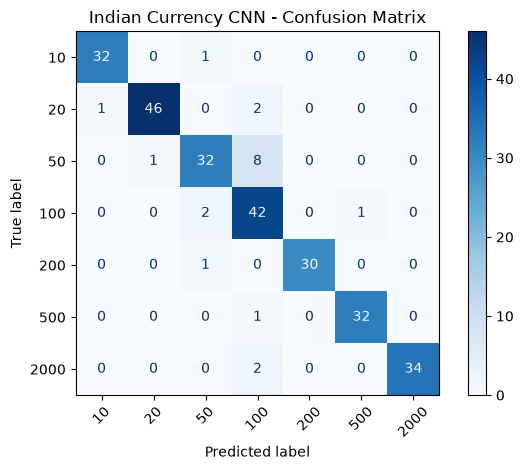

In [15]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

class_names = ["10", "20", "50", "100", "200", "500", "2000"]

cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

plt.title("Indian Currency CNN - Confusion Matrix")
plt.tight_layout()
plt.show()


In [16]:
app_code = '''
import streamlit as st
import tensorflow as tf
import numpy as np
from PIL import Image
from pathlib import Path

st.set_page_config(
    page_title="Indian Currency Recognition",
    page_icon="💵"
)

st.title("💵 Indian Currency Recognition")
st.write("Upload an Indian currency note to identify its denomination.")

MODEL_PATH = Path("currency_note_cnn.keras")

@st.cache_resource
def load_model():
    return tf.keras.models.load_model(MODEL_PATH)

model = load_model()

class_names = ["₹10", "₹20", "₹50", "₹100",
               "₹200", "₹500", "₹2000"]

uploaded_file = st.file_uploader(
    "Upload Currency Image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file:

    image = Image.open(uploaded_file).convert("RGB")

    st.image(image, caption="Uploaded Currency",
             use_container_width=True)

    if st.button("Recognize Currency"):

        resized_image = image.resize((128, 128))

        image_array = np.array(
            resized_image,
            dtype=np.float32
        )

        image_array = image_array / 255.0

        image_array = np.expand_dims(image_array, axis=0)

        predictions = model.predict(image_array, verbose=0)

        predicted_index = np.argmax(predictions[0])

        predicted_currency = class_names[predicted_index]

        confidence = predictions[0][predicted_index] * 100

        st.success("Recognition Completed!")

        st.metric(
            "Predicted Currency",
            predicted_currency
        )

        st.metric(
            "Confidence",
            f"{confidence:.2f}%"
        )

        st.subheader("Class Probabilities")

        for i, currency in enumerate(class_names):
            st.write(currency)
            st.progress(float(predictions[0][i]))
'''

print("Streamlit application code prepared!")

Streamlit application code prepared!


In [17]:
import subprocess
from pathlib import Path

Path("app.py").write_text(app_code)

process = subprocess.Popen([
    "streamlit",
    "run",
    "app.py",
    "--server.headless=true"
])

print("Streamlit server started!")
print("Open: http://localhost:8501")

Streamlit server started!
Open: http://localhost:8501


2026-11-25 22:23:44.588 Uvicorn server started on :::8502



  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8502
  Network URL: http://192.168.1.10:8502
  External URL: http://122.167.158.177:8502

